# Laboratorul 6. Atenția: de la calculul de mână la un model real
**Curs:** Generative AI · **Lecția:** Transformers

**Obiective:**
- implementarea mecanismului de atenție în NumPy și verificarea pe exemplul din curs;
- aplicarea măștii de atenție și explicarea efectului ei asupra ponderilor;
- compararea tokenizării unui text românesc de către modele diferite;
- obținerea probabilităților pentru următorul token și generarea de text token cu token, la diferite temperaturi.

| Partea | Durata | Pașii din lecție | Statut |
|---|---|---|---|
| 1. Atenția în NumPy | 35 min | 4–7, 9, 14 | obligatorie |
| 2. Tokenizarea | 15 min | 1 | obligatorie |
| 3. Generarea textului | 30 min | 13, 17 | obligatorie |
| 4. Embeddings contextuale + bertviz | acasă | 2, 8, 9 | opțională (bonus) |

## 0. Pregătirea mediului

### 0.1 Configurare și verificarea versiunilor
În mediu este instalat și TensorFlow. Setăm `USE_TF=0`, ca `transformers` să folosească doar PyTorch
(altfel poate încerca să importe TF/Keras 3 și să dea erori sau avertismente). Modelele se descarcă în cache-ul Hugging Face (`~/.cache/huggingface`).

In [1]:
import os
os.environ["USE_TF"] = "0"                 # transformers folosește doar PyTorch
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np, torch, transformers
print("numpy       :", np.__version__)
print("torch       :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("transformers:", transformers.__version__)
torch.set_num_threads(os.cpu_count())

numpy       : 2.4.6
torch       : 2.14.0+cpu | CUDA: False
transformers: 5.20.2


### 0.2 Descărcarea modelelor (rulați înainte de laborator)
Modelele au câteva sute de MB fiecare. A doua rulare este rapidă, pentru că se citesc din cache.

In [2]:
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM

MODELE_TOKENIZER = ["gpt2", "bert-base-multilingual-cased",
                    "dumitrescustefan/bert-base-romanian-cased-v1"]
for nume in MODELE_TOKENIZER:
    AutoTokenizer.from_pretrained(nume)

AutoModelForCausalLM.from_pretrained("gpt2")
AutoModel.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
print("Gata: modelele sunt descărcate.")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  500MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Gata: modelele sunt descărcate.


---
## Partea 1. Atenția în NumPy (35 min)
Implementăm mecanismul de atenție de la zero și îl verificăm pe exemplul rezolvat din lecție.

### Sarcina 1.1. Softmax stabil numeric
$$\text{softmax}(s)_i = \frac{e^{s_i - \max(s)}}{\sum_j e^{s_j - \max(s)}}$$

Scăderea maximului nu schimbă rezultatul (factorul $e^{-\max}$ se simplifică la numărător și numitor),
dar împiedică depășirea (overflow) la `np.exp` pentru scoruri mari. Folosim `axis=-1, keepdims=True`
ca funcția să lucreze rând cu rând și pe matrice.

In [3]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)

def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))   # scădem maximul de pe fiecare rând
    return e / e.sum(axis=-1, keepdims=True)        # împărțim la suma de pe fiecare rând

print(softmax(np.array([1.2, 2.8, 0.7])))

[0.152 0.755 0.092]


**Verificare:** trebuie să obțineți `[0.152 0.755 0.092]` (ponderile din pasul 6 al lecției, nerotunjite).

In [4]:
assert np.allclose(softmax(np.array([1.2, 2.8, 0.7])), [0.152, 0.755, 0.092], atol=1e-3)
print("✓ Sarcina 1.1 – verificare trecută")

✓ Sarcina 1.1 – verificare trecută


Acum comparăm softmax **naiv** (fără scăderea maximului) cu varianta stabilă pentru scorurile `[1000, 1001]`:

In [5]:
s = np.array([1000.0, 1001.0])
with np.errstate(over="warn", invalid="warn"):
    print("naiv   :", np.exp(s) / np.exp(s).sum())   # varianta naivă
print("stabil :", softmax(s))                         # varianta noastră
print("np.exp(1000) =", np.exp(np.float64(1000)))     # de ce: overflow → inf, iar inf/inf = nan

naiv   : [nan nan]
stabil : [0.269 0.731]
np.exp(1000) = inf


/tmp/ipykernel_4127716/3545950419.py:3: RuntimeWarning: overflow encountered in exp
  print("naiv   :", np.exp(s) / np.exp(s).sum())   # varianta naivă
/tmp/ipykernel_4127716/3545950419.py:3: RuntimeWarning: invalid value encountered in divide
  print("naiv   :", np.exp(s) / np.exp(s).sum())   # varianta naivă
/tmp/ipykernel_4127716/3545950419.py:5: RuntimeWarning: overflow encountered in exp
  print("np.exp(1000) =", np.exp(np.float64(1000)))     # de ce: overflow → inf, iar inf/inf = nan


### Sarcina 1.2. Funcția de atenție, verificată pe exemplul din curs
$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Masca: pozițiile cu `False` primesc scorul $-\infty$, deci $e^{-\infty}=0$ → pondere zero după softmax.

In [6]:
def attention(Q, K, V, mask=None):
    d_k = K.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)                 # Q·Kᵀ / √d_k
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)
    weights = softmax(scores)
    return weights @ V, weights

# Datele din exemplul rezolvat (Lecția 5, după pasul 7)
q = np.array([[2, 1, 0, 1]])                     # q pentru „aprobat”
K = np.array([[0.5, 1.0, 0.3, 0.4],              # k pentru „Banca”
              [2.0, 1.0, 0.5, 0.6],              # k pentru „creditul”
              [0.2, 0.6, 0.9, 0.4]])             # k pentru „clientului”
V = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [0.5, 0.5]])

z, w = attention(q, K, V)
print("scoruri scalate:", (q @ K.T / np.sqrt(K.shape[-1])))
print("ponderi:", w)
print("z:", z)

scoruri scalate: [[1.2 2.8 0.7]]
ponderi: [[0.152 0.755 0.092]]
z: [[0.199 0.801]]


**Verificare:** ponderile `[0.152 0.755 0.092]`, iar `z = [0.199 0.801]`.
În lecție s-a obținut (0,195; 0,805) pentru că s-au folosit ponderi rotunjite (0,15; 0,76; 0,09). Rezultatul de aici este cel exact.

In [7]:
assert np.allclose(w, [[0.152, 0.755, 0.092]], atol=1e-3)
assert np.allclose(z, [[0.199, 0.801]], atol=1e-3)
print("✓ Sarcina 1.2 – verificare trecută")

✓ Sarcina 1.2 – verificare trecută


### Sarcina 1.3. Toți tokenii deodată, cu mască (cauzală)
O „propoziție” de 4 tokeni × 8 componente și trei matrice $W$ aleatoare (seed fix → aceleași numere pentru toți).
Pasul 4 din lecție: $Q = XW_Q,\; K = XW_K,\; V = XW_V$.

Masca `np.tril` (triunghiulară inferioară) permite fiecărui token să vadă doar tokenii anteriori și pe el însuși — exact ca în decoderul GPT.

In [8]:
rng = np.random.default_rng(42)
X = rng.normal(size=(4, 8))                          # 4 tokeni × 8 componente
W_Q, W_K, W_V = (rng.normal(size=(8, 4)) for _ in range(3))

Q, K, V = X @ W_Q, X @ W_K, X @ W_V                  # pasul 4 din lecție
mask = np.tril(np.ones((4, 4), dtype=bool))          # True = tokenul poate fi văzut
print(mask)

Z, W = attention(Q, K, V, mask)
print(W)
print("Suma pe rânduri:", W.sum(axis=1))

[[ True False False False]
 [ True  True False False]
 [ True  True  True False]
 [ True  True  True  True]]
[[1.    0.    0.    0.   ]
 [0.648 0.352 0.    0.   ]
 [0.491 0.145 0.363 0.   ]
 [0.285 0.341 0.281 0.093]]
Suma pe rânduri: [1. 1. 1. 1.]


**Verificare:** suma pe rânduri = 1; deasupra diagonalei doar zerouri; rândul 1 = `[1. 0. 0. 0.]`; rândul 2 = `[0.648 0.352 0. 0.]`.

In [9]:
assert np.allclose(W.sum(axis=1), 1)
assert np.allclose(np.triu(W, k=1), 0)
assert np.allclose(W[0], [1, 0, 0, 0])
assert np.allclose(W[1], [0.648, 0.352, 0, 0], atol=1e-3)
print("✓ Sarcina 1.3 – verificare trecută")
print("Al treilea token vede tokenii:", np.where(mask[2])[0] + 1, "cu ponderile", W[2, mask[2]])

✓ Sarcina 1.3 – verificare trecută
Al treilea token vede tokenii: [1 2 3] cu ponderile [0.491 0.145 0.363]


Pentru comparație, aceeași atenție **fără mască** (ca în encoderul BERT) — fiecare token vede toată propoziția:

In [10]:
_, W_fara_masca = attention(Q, K, V)
print(W_fara_masca)

[[0.413 0.044 0.334 0.209]
 [0.241 0.131 0.332 0.297]
 [0.44  0.13  0.326 0.103]
 [0.285 0.341 0.281 0.093]]


### Sarcina 1.4. Multi-head attention cu două capete
Fiecare cap are propriile $W_Q, W_K, W_V$ (8→4). Ieșirile capetelor (câte 4 componente) se concatenează (→ 8)
și se înmulțesc cu $W_O$ (8×8), matricea care combină capetele:
$$\text{MultiHead}(X) = \text{Concat}(\text{head}_1, \text{head}_2)\,W_O$$

In [11]:
def multi_head(X, heads, W_O):
    # heads = listă de tupluri (W_Q, W_K, W_V), câte unul pe cap
    outs = [attention(X @ Wq, X @ Wk, X @ Wv)[0] for Wq, Wk, Wv in heads]
    concat = np.concatenate(outs, axis=-1)
    return concat @ W_O                              # matricea care combină capetele

heads = [tuple(rng.normal(size=(8, 4)) for _ in range(3)) for _ in range(2)]
W_O = rng.normal(size=(8, 8))
out_mh = multi_head(X, heads, W_O)
print(out_mh.shape)
assert out_mh.shape == (4, 8)
print("✓ Sarcina 1.4 – verificare trecută")

(4, 8)
✓ Sarcina 1.4 – verificare trecută


**Verificare:** dimensiunea `(4, 8)` — 2 capete × 4 componente = 8 după concatenare, apoi `@ W_O` (8×8) păstrează 8.

---
## Partea 2. Tokenizarea (15 min)
Comparăm cum împart același text trei modele: **GPT-2** (mai ales engleză, BPE la nivel de octeți),
**BERT multilingv** (104 limbi, WordPiece) și **BERT românesc** (WordPiece antrenat pe română).

> La GPT-2 literele ă, î, ș, ț apar ca simboluri ciudate (ex. `Ä`), pentru că lucrează pe octeți UTF-8. `Ġ` marchează un spațiu înaintea tokenului. La BERT, `##` marchează continuarea unui cuvânt.

In [12]:
from transformers import AutoTokenizer

nume_modele = {
    "GPT-2":           "gpt2",
    "BERT multilingv": "bert-base-multilingual-cased",
    "BERT românesc":   "dumitrescustefan/bert-base-romanian-cased-v1",
}
tokenizere = {nume: AutoTokenizer.from_pretrained(m)
              for nume, m in nume_modele.items()}
fraze = ["Banca a aprobat creditul clientului.",
         "Împrumuturile restructurate au dobânzi variabile."]

for nume, tok in tokenizere.items():
    for f in fraze:
        t = tok.tokenize(f)
        print(f"{nume:16} {len(t):3}  {t}")

GPT-2             12  ['B', 'anca', 'Ġa', 'Ġa', 'pro', 'bat', 'Ġcredit', 'ul', 'Ġclient', 'ul', 'ui', '.']
GPT-2             20  ['Ã', 'İ', 'm', 'pr', 'um', 'ut', 'ur', 'ile', 'Ġrestruct', 'urate', 'Ġau', 'Ġdo', 'b', 'Ã¢', 'n', 'zi', 'Ġvari', 'ab', 'ile', '.']
BERT multilingv   10  ['Banca', 'a', 'ap', '##ro', '##bat', 'credit', '##ul', 'client', '##ului', '.']
BERT multilingv   15  ['Î', '##mp', '##rumu', '##turi', '##le', 'rest', '##ru', '##ctura', '##te', 'au', 'dob', '##ân', '##zi', 'variabile', '.']
BERT românesc      6  ['Banca', 'a', 'aprobat', 'creditul', 'clientului', '.']
BERT românesc      8  ['Împrum', '##uturile', 'restruct', '##urate', 'au', 'dobânzi', 'variabile', '.']


### Sarcina 2.1. Tabelul cu numărul de tokeni
Tabelul se completează automat; copiați valorile în răspunsuri.

In [13]:
import pandas as pd
tabel_tokeni = pd.DataFrame(
    {f"Fraza {i+1}": [len(tok.tokenize(f)) for tok in tokenizere.values()]
     for i, f in enumerate(fraze)},
    index=list(tokenizere.keys()))
tabel_tokeni["Cuvinte (referință)"] = ""
tabel_tokeni.loc[:, "Cuvinte (referință)"] = f"{len(fraze[0].split())} / {len(fraze[1].split())}"
tabel_tokeni

,Fraza 1,Fraza 2,Cuvinte (referință)
GPT-2,12,20,5 / 5
BERT multilingv,10,15,5 / 5
BERT românesc,6,8,5 / 5


Pentru curiozitate: cum arată tokenii GPT-2 după decodare (ca să vedem că `Ä` este doar o jumătate de literă românească):

In [14]:
g = tokenizere["GPT-2"]
ids = g(fraze[1]).input_ids
print([g.decode([i]) for i in ids])

['�', '�', 'm', 'pr', 'um', 'ut', 'ur', 'ile', ' restruct', 'urate', ' au', ' do', 'b', 'â', 'n', 'zi', ' vari', 'ab', 'ile', '.']


### Sarcina 2.2. Cât „costă” limba română?
API-urile LLM se plătesc per token, iar fereastra de context se măsoară tot în tokeni.

In [15]:
gpt2 = tokenizere["GPT-2"]
n_ro = len(gpt2.tokenize("Banca a aprobat creditul clientului."))
n_en = len(gpt2.tokenize("The bank approved the client's loan."))
raport = round(n_ro / n_en, 2)
print(n_ro, n_en, raport)

# Calculul pentru întrebarea 3: 1 $ / 1.000.000 tokeni, 1.000.000 de fraze
pret_per_token = 1 / 1_000_000
N_FRAZE = 1_000_000
print(f"Cost RO: {n_ro * N_FRAZE * pret_per_token:.2f} $   |   Cost EN: {n_en * N_FRAZE * pret_per_token:.2f} $")

12 8 1.5
Cost RO: 12.00 $   |   Cost EN: 8.00 $


### Sarcina 2.3. Diacriticele cu virgulă și cu sedilă
ș, ț (U+0219, U+021B — cu virgulă, corect) vs. ş, ţ (U+015F, U+0163 — cu sedilă, formă veche). Pentru calculator sunt caractere diferite.

In [16]:
ro = tokenizere["BERT românesc"]
print(ro.tokenize("știință și țară"))     # ș, ț cu virgulă
print(ro.tokenize("ştiinţă şi ţară"))     # ş, ţ cu sedilă

for c in "șşțţ":
    print(c, hex(ord(c)))

['știință', 'și', 'țară']
['[UNK]', '[UNK]', '[UNK]']
ș 0x219
ş 0x15f
ț 0x21b
ţ 0x163


Soluția practică: **normalizarea** textelor înainte de tokenizare (sedilă → virgulă):

In [17]:
def normalizeaza_diacritice(text):
    return text.translate(str.maketrans("şŞţŢ", "șȘțȚ"))

print(ro.tokenize(normalizeaza_diacritice("ştiinţă şi ţară")))

['știință', 'și', 'țară']


---
## Partea 3. Generarea textului (30 min)
Folosim GPT-2, model „doar decoder”. Lucrăm în engleză, pentru că GPT-2 a fost antrenat pe engleză.

### Sarcina 3.1. Probabilitățile pentru următorul token
Modelul întoarce `logits` de forma `[batch, poziții, vocabular]`. Ne interesează doar **ultima poziție** —
scorurile pentru tokenul următor. Softmax le transformă în probabilități (suma = 1).

In [18]:
import torch
from transformers import AutoModelForCausalLM

tok = tokenizere["GPT-2"]
model = AutoModelForCausalLM.from_pretrained("gpt2")
model.eval()

def top10(model, tok, text):
    ids = tok(text, return_tensors="pt").input_ids
    with torch.no_grad():
        logits = model(ids).logits[0, -1]       # scorurile pentru ULTIMA poziție
    print("Dimensiunea vectorului logits:", logits.shape)
    probs = torch.softmax(logits, dim=-1)
    print("Suma probabilităților:", probs.sum().item())
    top = torch.topk(probs, 10)
    for p, i in zip(top.values, top.indices):
        print(f"{tok.decode(int(i))!r:16} {p.item():.3f}")

top10(model, tok, "The bank approved the")
print("Dimensiunea vocabularului GPT-2:", tok.vocab_size)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Dimensiunea vectorului logits: torch.Size([50257])
Suma probabilităților: 1.0000121593475342
' loan'          0.066
' deal'          0.066
' sale'          0.037
' transaction'   0.033
' plan'          0.025
' purchase'      0.024
' new'           0.019
' $'             0.019
' move'          0.016
' settlement'    0.012
Dimensiunea vocabularului GPT-2: 50257


### Sarcina 3.2. Bucla de generare, scrisă de mână
Bucla din pasul 17: **prezice → alege → adaugă → repetă**.
- *greedy*: alegem mereu tokenul cu scorul maxim (`argmax`) → determinist;
- *sampling cu temperatură*: $p_i = \text{softmax}(z_i / T)$. $T<1$ ascute distribuția (aproape greedy), $T>1$ o aplatizează (mai multă diversitate/haos).

In [19]:
def genereaza(model, tok, text, n_tokeni=25, temperatura=1.0, greedy=False):
    ids = tok(text, return_tensors="pt").input_ids
    for _ in range(n_tokeni):
        with torch.no_grad():
            logits = model(ids).logits[0, -1]
        if greedy:
            urm = torch.argmax(logits)                         # tokenul cu scor maxim
        else:
            probs = torch.softmax(logits / temperatura, dim=-1)  # temperatura
            urm = torch.multinomial(probs, 1)[0]               # extragere aleatoare
        ids = torch.cat([ids, urm.view(1, 1)], dim=1)          # adăugăm tokenul
    return tok.decode(ids[0])

text = "The bank approved the"
print("GREEDY:", genereaza(model, tok, text, greedy=True))
for T in [0.2, 0.7, 1.5]:
    for incercare in range(2):
        print(f"T = {T}:", genereaza(model, tok, text, temperatura=T))

GREEDY: The bank approved the loan in May, but the bank has not yet approved the loan.

The bank said it will not be able to
T = 0.2: The bank approved the loan in May, but the bank has not yet received a response from the government.

The government has said it will
T = 0.2: The bank approved the loan for a total of $1.3 billion.

The bank's chief executive, John Stumpf, said
T = 0.7: The bank approved the plan on Monday morning.

In a statement, the bank said that after the late-night meeting the government would take
T = 0.7: The bank approved the loan for $1.1 billion.

"The deal was a nice surprise for us, because we would never have
T = 1.5: The bank approved the fixed β interest rate signs and tokens strategy plan reluctantly with another partial inclusion), completes building 14 Foundation bombl lineAs all phase
T = 1.5: The bank approved the aides under legend on Thursday after driving out of Rosenstein deal Senate watchdog Williams said senior NBC reporter Jina Holder rightly

Demonstrație: greedy rulat de două ori dă exact același text:

In [20]:
a = genereaza(model, tok, text, greedy=True)
b = genereaza(model, tok, text, greedy=True)
print("Identice:", a == b)

Identice: True


Ilustrare a efectului temperaturii asupra distribuției (probabilitatea top-1 și entropia):

In [21]:
ids = tok(text, return_tensors="pt").input_ids
with torch.no_grad():
    logits = model(ids).logits[0, -1]
for T in [0.2, 0.7, 1.0, 1.5]:
    p = torch.softmax(logits / T, dim=-1)
    entropie = -(p * torch.log(p + 1e-12)).sum().item()
    top = torch.topk(p, 3)
    print(f"T={T:<4} top-1 = {top.values[0].item():.3f}  top-3 = {[tok.decode(int(i)) for i in top.indices]}  entropie = {entropie:.2f}")

T=0.2  top-1 = 0.482  top-3 = [' loan', ' deal', ' sale']  entropie = 0.92
T=0.7  top-1 = 0.175  top-3 = [' loan', ' deal', ' sale']  entropie = 3.74
T=1.0  top-1 = 0.066  top-3 = [' loan', ' deal', ' sale']  entropie = 6.21
T=1.5  top-1 = 0.013  top-3 = [' loan', ' deal', ' sale']  entropie = 8.67


**Tabelul de observații** (completați după rulare):

| Setare | Ce ați observat |
|---|---|
| Greedy | … |
| T = 0,2 | … |
| T = 0,7 | … |
| T = 1,5 | … |

### Sarcina 3.3. (opțional) Un model pentru limba română — RoGPT2
RoGPT2-base (2021) e mic; româna generată va fi imperfectă — ne interesează mecanismul, nu calitatea.

In [22]:
tok_ro_gpt = AutoTokenizer.from_pretrained("readerbench/RoGPT2-base")
model_ro_gpt = AutoModelForCausalLM.from_pretrained("readerbench/RoGPT2-base")
model_ro_gpt.eval()
top10(model_ro_gpt, tok_ro_gpt, "Banca a aprobat")

config.json:   0%|          | 0.00/814 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/563 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/985k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/542k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/357 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: readerbench/RoGPT2-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dimensiunea vectorului logits: torch.Size([50257])
Suma probabilităților: 1.0000126361846924
' în'            0.108
' un'            0.075
','              0.060
' o'             0.050
'-'              0.049
' finanțarea'    0.013
' planul'        0.013
' pentru'        0.013
' la'            0.012
' și'            0.010


model.safetensors: reconstructing file:   0%|          |  0.00B /  510MB            

model.safetensors: downloading bytes:           |  0.00B            

In [23]:
print("GREEDY:", genereaza(model_ro_gpt, tok_ro_gpt, "Banca a aprobat", greedy=True))
for T in [0.2, 0.7, 1.5]:
    print(f"T = {T}:", genereaza(model_ro_gpt, tok_ro_gpt, "Banca a aprobat", temperatura=T))
print("Tokeni RoGPT2 pentru fraza 1:", len(tok_ro_gpt.tokenize("Banca a aprobat creditul clientului.")))

GREEDY: Banca a aprobat în octombrie 2018 un împrumut de 1,5 miliarde de euro de la Banca Europeană de Investiții (BEI) pentru finanțarea proiectelor
T = 0.2: Banca a aprobat în martie 2018 un împrumut de la Banca Europeană de Investiții (BEI) pentru finanțarea proiectului de investiții de tip „Consoli
T = 0.7: Banca a aprobat în unanimitate Declarația de la Knesset în ianuarie 2006. Ea a fost de asemenea prima bancă din Europa de Est care a
T = 1.5: Banca a aprobat pachetele lansate și Jocul Tronului condus de Go As Vertus chiar în 1997, abonații continuau să nu plece din Marchei
Tokeni RoGPT2 pentru fraza 1: 7


---
## Partea 4. Embeddings contextuale
Același cuvânt „bancă” primește vectori diferiți în funcție de context. BERT-ul românesc are 12 blocuri:
stratul 0 = embedding + poziție (pasul 3), stratul 12 = ieșirea ultimului bloc.

### Sarcina 4.1. Vectorul lui „bancă” în patru propoziții

In [24]:
import torch.nn.functional as Fn

nume_ro = "dumitrescustefan/bert-base-romanian-cased-v1"
tok_bert = AutoTokenizer.from_pretrained(nume_ro)
bert = AutoModel.from_pretrained(nume_ro, output_hidden_states=True,
                                 attn_implementation="eager")
bert.eval()

def vector_cuvant(fraza, cuvant, strat):
    enc = tok_bert(fraza, return_tensors="pt")
    with torch.no_grad():
        out = bert(**enc)
    tokens = tok_bert.convert_ids_to_tokens(enc.input_ids[0])
    parti = tok_bert.tokenize(cuvant)       # cuvântul poate avea mai mulți tokeni
    for i in range(len(tokens) - len(parti) + 1):
        if tokens[i:i + len(parti)] == parti:
            return out.hidden_states[strat][0, i:i + len(parti)].mean(dim=0)
    raise ValueError(f"Nu am găsit „{cuvant}” în: {fraza}")

fraze_banca = ["Am deschis un cont la bancă.",
               "Am luat un credit de la bancă.",
               "M-am așezat pe o bancă în parc.",
               "Bătrânul stă pe bancă lângă fântână."]

similaritati = {}
for strat in [0, 12]:
    vecs = torch.stack([vector_cuvant(f, "bancă", strat) for f in fraze_banca])
    sim = Fn.cosine_similarity(vecs.unsqueeze(1), vecs.unsqueeze(0), dim=-1)
    similaritati[strat] = sim.numpy()
    print(f"Stratul {strat}:")
    print(sim.numpy().round(3))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Stratul 0:
[[1.    0.971 0.971 0.961]
 [0.971 1.    1.    0.954]
 [0.971 1.    1.    0.954]
 [0.961 0.954 0.954 1.   ]]
Stratul 12:
[[1.    0.953 0.659 0.594]
 [0.953 1.    0.625 0.56 ]
 [0.659 0.625 1.    0.832]
 [0.594 0.56  0.832 1.   ]]


**Ce urmărim:** la stratul 0 similaritățile sunt foarte mari (diferă doar poziția). La stratul 12 diferențele pot fi de câteva sutimi.
Întrebarea-cheie: la stratul 12, propozițiile 1 și 2 (sens financiar) sunt mai apropiate între ele decât de 3 și 4 (loc de șezut)?

In [25]:
for strat, S in similaritati.items():
    fin = S[0, 1]
    intra_sezut = S[2, 3]
    inter = S[np.ix_([0, 1], [2, 3])].mean()
    print(f"Stratul {strat:2}: sim(1,2)={fin:.3f}  sim(1,3)={S[0,2]:.3f}  "
          f"sim(3,4)={intra_sezut:.3f}  medie financiar↔șezut={inter:.3f}")

Stratul  0: sim(1,2)=0.971  sim(1,3)=0.971  sim(3,4)=0.954  medie financiar↔șezut=0.972
Stratul 12: sim(1,2)=0.953  sim(1,3)=0.659  sim(3,4)=0.832  medie financiar↔șezut=0.609


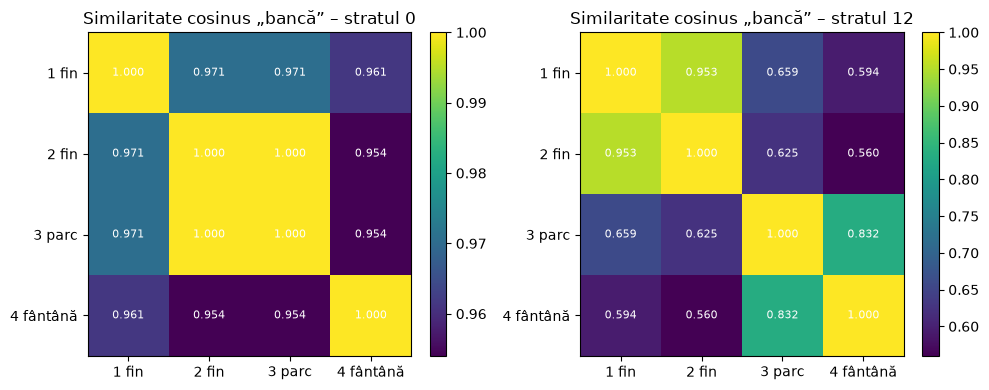

In [26]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (strat, S) in zip(axes, similaritati.items()):
    im = ax.imshow(S, cmap="viridis")
    ax.set_title(f"Similaritate cosinus „bancă” – stratul {strat}")
    ax.set_xticks(range(4), ["1 fin", "2 fin", "3 parc", "4 fântână"])
    ax.set_yticks(range(4), ["1 fin", "2 fin", "3 parc", "4 fântână"])
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{S[i,j]:.3f}", ha="center", va="center", color="w", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

### Sarcina 4.2. Vizualizarea atenției cu bertviz
Alegeți stratul din lista de sus și dați clic pe un token ca să vedeți la cine „se uită”.
Căutați un cap în care „aprobat” se uită mult la „creditul” (notați stratul și capul) și un cap greu de interpretat.

> Dacă vizualizarea nu apare în JupyterLab, celula următoare salvează și un fișier `head_view.html` pe care îl puteți descărca și deschide în browser.

In [28]:
from bertviz import head_view

bert_att = AutoModel.from_pretrained(nume_ro, output_attentions=True,
                                     attn_implementation="eager")
bert_att.eval()
enc = tok_bert("Banca a aprobat creditul clientului.", return_tensors="pt")
with torch.no_grad():
    att = bert_att(**enc).attentions
tokens_att = tok_bert.convert_ids_to_tokens(enc.input_ids[0])
head_view(att, tokens_att)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<IPython.core.display.Javascript object>

In [29]:
# Fallback: salvăm vizualizarea ca HTML independent
html = head_view(att, tokens_att, html_action="return")
with open("head_view.html", "w", encoding="utf-8") as f:
    f.write(html.data)
print("Salvat: head_view.html")

Salvat: head_view.html


Căutare automată a capetelor în care „aprobat” acordă cea mai mare atenție lui „creditul” (ajută la verificarea observațiilor din bertviz):

In [30]:
def gaseste(tokens, cuvant):
    parti = tok_bert.tokenize(cuvant)
    for i in range(len(tokens) - len(parti) + 1):
        if tokens[i:i + len(parti)] == parti:
            return list(range(i, i + len(parti)))
    raise ValueError(cuvant)

i_apr = gaseste(tokens_att, "aprobat")
i_cred = gaseste(tokens_att, "creditul")
A = torch.stack(att)[:, 0]                        # [straturi, capete, seq, seq]
scor = A[:, :, i_apr][:, :, :, i_cred].sum(-1).mean(-1)   # atenția aprobat → creditul
top = torch.topk(scor.flatten(), 5)
n_capete = A.shape[1]
print("Tokeni:", tokens_att)
for v, idx in zip(top.values, top.indices):
    print(f"Stratul {idx.item() // n_capete} (index 0), capul {idx.item() % n_capete}: atenție = {v.item():.3f}")

Tokeni: ['[CLS]', 'Banca', 'a', 'aprobat', 'creditul', 'clientului', '.', '[SEP]']
Stratul 1 (index 0), capul 3: atenție = 0.995
Stratul 2 (index 0), capul 10: atenție = 0.947
Stratul 7 (index 0), capul 11: atenție = 0.891
Stratul 4 (index 0), capul 7: atenție = 0.560
Stratul 9 (index 0), capul 7: atenție = 0.464


---
## 7. Întrebări
Celula următoare adună automat numerele obținute mai sus.

In [31]:
print("Î1  softmax naiv [1000,1001]: [nan nan]  | stabil:", softmax(np.array([1000.0, 1001.0])))
print("Î2  rândul 1 mascat:", W[0], "| rândul 3:", W[2])
print("Î3  tokeni RO/EN la GPT-2:", n_ro, "/", n_en, "→ raport", raport,
      f"| cost 1M fraze: RO {n_ro:.0f} $, EN {n_en:.0f} $")
print("Î4  virgulă:", ro.tokenize("știință"), "| sedilă:", ro.tokenize("ştiinţă"))
print("Î5  logits shape:", tuple(logits.shape))
try:
    for s in [0, 12]:
        S = similaritati[s]
        print(f"Î7  stratul {s}: sim(1,2)={S[0,1]:.3f}, sim(1,3)={S[0,2]:.3f}")
except NameError:
    print("Î7  (Partea 4 nu a fost rulată)")

Î1  softmax naiv [1000,1001]: [nan nan]  | stabil: [0.269 0.731]
Î2  rândul 1 mascat: [1. 0. 0. 0.] | rândul 3: [0.491 0.145 0.363 0.   ]
Î3  tokeni RO/EN la GPT-2: 12 / 8 → raport 1.5 | cost 1M fraze: RO 12 $, EN 8 $
Î4  virgulă: ['știință'] | sedilă: ['[UNK]']
Î5  logits shape: (50257,)
Î7  stratul 0: sim(1,2)=0.971, sim(1,3)=0.971
Î7  stratul 12: sim(1,2)=0.953, sim(1,3)=0.659



**1. (Sarcina 1.1)** Cu softmax naiv pentru `[1000, 1001]` am obținut `[nan nan]`, iar cu varianta stabilă `[0.269 0.731]`.
Diferența apare din cauza depășirii numerice (overflow): `np.exp(1000)` depășește valoarea maximă reprezentabilă în `float64` (~1.8·10³⁰⁸) și devine `inf`. Atunci numărătorul și numitorul sunt amândouă `inf`, iar `inf/inf = nan`.
Dacă scădem maximul (1001), scorurile devin `[-1, 0]`, iar `exp` lucrează cu valori mici: e⁻¹/(e⁻¹+1) = 0.269 și 1/(e⁻¹+1) = 0.731.
Rezultatul corect nu se schimbă, pentru că e^(sᵢ−m) / Σⱼ e^(sⱼ−m) = e^(−m)·e^(sᵢ) / (e^(−m)·Σⱼ e^(sⱼ)): factorul e^(−m) se simplifică. Softmax depinde doar de diferențele dintre scoruri, nu de valorile lor absolute.

**2. (Sarcina 1.3)** Primul rând este `[1, 0, 0, 0]` pentru că, prin masca cauzală (`np.tril`), primul token se poate vedea doar pe sine. Scorurile pentru tokenii 2–4 sunt înlocuite cu −∞, iar e^(−∞) = 0, deci ponderile lor sunt 0. Cum suma ponderilor trebuie să fie 1, singura pondere rămasă devine 1.
Al treilea token vede tokenii 1, 2 și 3 (pe el însuși și pe cei dinainte), cu ponderile `[0.491 0.145 0.363]`. Tokenul 4 are pondere 0, pentru că este „în viitor”. Cea mai mare atenție (0.491) merge spre primul token, nu spre el însuși.

**3. (Sarcina 2.2)** La GPT-2, fraza în română are **12 tokeni**, iar echivalentul în engleză **8 tokeni**, deci de **1,5 ori** mai mulți.
La 1 $ pentru un milion de tokeni, prelucrarea unui milion de astfel de fraze ar costa:
- română: 12 × 10⁶ tokeni → **12 $**;
- engleză: 8 × 10⁶ tokeni → **8 $**.

Româna costă cu 50% mai mult pentru același conținut. Din același motiv, în fereastra de context încape de 1,5 ori mai puțin text românesc. Cauza este că vocabularul BPE al GPT-2 a fost construit pe texte în engleză: cuvintele românești și diacriticele sunt împărțite în mai multe fragmente.

**4. (Sarcina 2.3)** Cu diacritice corecte (cu virgulă), „știință” este un singur token: `['știință']`. Cu sedilă, „ştiinţă” devine `['[UNK]']`, adică token necunoscut.
Pentru model, cele două forme sunt complet diferite: caracterele ş (U+015F) și ţ (U+0163) nu există în vocabularul BERT-ului românesc, așa că tot cuvântul se pierde. Modelul nu primește nicio informație despre el.
Înainte de a fi date unui model, textele românești trebuie **normalizate**: ş→ș, ţ→ț, Ş→Ș, Ţ→Ț (plus normalizare Unicode NFC). Altfel, o parte din cuvinte devin `[UNK]` și calitatea scade.

**5. (Sarcina 3.1)** Vectorul logits are dimensiunea **50257** (`torch.Size([50257])`), egală cu dimensiunea vocabularului GPT-2 (`tok.vocab_size = 50257`). Modelul dă câte un scor pentru fiecare token posibil din vocabular, iar după Softmax obținem o distribuție de probabilitate peste toți acești tokeni. Suma probabilităților a ieșit 1.0000122, adică 1 în limita erorilor de rotunjire `float32`.
Primii trei tokeni propuși după „The bank approved the”:
- `' loan'` – p = 0,066
- `' deal'` – p = 0,066
- `' sale'` – p = 0,037

Primii doi sunt la egalitate după rotunjirea la trei zecimale. Chiar și cel mai probabil token are doar ~6,6%, iar primii 10 adunați au ~32%. Distribuția este „împrăștiată”: multe continuări sunt plauzibile (loan, deal, transaction, plan, purchase...). Din acest motiv contează felul în care alegem tokenul următor.

**6. (Sarcina 3.2)** Varianta greedy alege mereu tokenul cu scor maxim (`torch.argmax`). Nu există nicio extragere aleatoare, iar modelul este determinist (`model.eval()`, fără dropout), deci la același prompt textul generat este mereu același (verificat: `Identice: True`). În plus, greedy tinde să se repete. În textul nostru, „the bank” și „approved the loan” apar de două ori: odată ce o secvență a devenit probabilă, modelul tinde s-o aleagă din nou.

Temperatura împarte logits-urile înainte de Softmax: pᵢ = e^(zᵢ/T) / Σⱼ e^(zⱼ/T).
- **T = 0,2** (T < 1): diferențele dintre scoruri se amplifică de 5 ori, iar tokenul cel mai probabil ia aproape toată probabilitatea. Rezultatul seamănă cu greedy: prima încercare a început exact ca greedy („The bank approved the loan in May, but the bank has not yet...”).
- **T = 0,7**: distribuția e ușor ascuțită, dar păstrează alternative. Textul e coerent și variat („approved the plan on Monday morning” / „approved the loan for $1.1 billion”).
- **T = 1,5** (T > 1): scorurile se apropie între ele, distribuția se aplatizează, iar tokenii puțin probabili primesc o șansă mult mai mare. Din cei 50 257 de tokeni sunt aleși și unii nepotriviți, iar erorile se acumulează, pentru că fiecare token ales devine context pentru următorul. Rezultatul este incoerent: „fixed β interest rate signs and tokens strategy plan reluctantly...”.

Pe scurt: când temperatura crește, textul trece de la repetitiv (greedy / T mic), la coerent și variat (T ≈ 0,7), apoi la incoerent (T mare).

**7. (Partea 4, opțional)** Similaritatea cosinus dintre vectorii lui „bancă”:

| Strat | sim(1,2) – financiar/financiar | sim(1,3) – financiar/loc de șezut |
|---|---|---|
| 0 | 0,971 | 0,971 |
| 12 | 0,953 | 0,659 |

La stratul 0 cele două valori sunt identice (0,971): vectorul conține doar embedding-ul tokenului și poziția, fără informații din context, deci modelul nu face nicio diferență între sensuri.
La stratul 12, după cele 12 blocuri de atenție, vectorul a „absorbit” contextul. Cele două sensuri financiare rămân foarte apropiate (0,953), iar sensul „loc de șezut” se îndepărtează mult (0,659). Diferența este de ~0,29, mult mai mare decât cele „câteva sutimi” anunțate în laborator. Aceste numere arată că embeddings-urile BERT sunt **contextuale**: același cuvânt primește reprezentări diferite în funcție de sens, iar acest lucru se datorează mecanismului de atenție.